# You Are Traveling Through Another Dimension
## 3D Scatter Plot: Life Expectancy, Fertility Rate, and Internet Use by Country (2023)

Data: World Bank, World Development Indicators, three indicators for 2023:
* `SP.DYN.LE00.IN`: life expectancy at birth, total (years)
* `SP.DYN.TFRT.IN`: fertility rate, total (births per woman)
* `IT.NET.USER.ZS`: individuals using the Internet (percent of population)

Only individual countries and territories with all three values for 2023 are kept (181 rows). Regional aggregates such as "World" or "Euro area" were removed.

**Rotation:** the `%matplotlib ipympl` line makes the chart interactive, so you can click and drag to rotate it. If you get an error, run `%pip install ipympl` in a new cell, restart the kernel, delete that cell, and run all cells again.

In [1]:
%matplotlib ipympl

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.figure import Figure

In [3]:
countries = pd.read_csv('world_bank_life_fertility_internet_2023.csv')
countries.head()

,country,country_code,region,income_group,year,life_expectancy_years,fertility_births_per_woman,internet_users_percent
0,Afghanistan,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2023,66.035,4.840,15.928
1,Albania,ALB,Europe & Central Asia,Upper middle income,2023,79.602,1.348,83.136
2,Algeria,DZA,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,2023,76.261,2.766,76.198
3,Andorra,AND,Europe & Central Asia,High income,2023,84.041,1.082,94.215
4,Angola,AGO,Sub-Saharan Africa,Lower middle income,2023,64.617,5.124,37.886


In [4]:
countries.info()

<class 'pandas.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   country                     181 non-null    str    
 1   country_code                181 non-null    str    
 2   region                      181 non-null    str    
 3   income_group                181 non-null    str    
 4   year                        181 non-null    int64  
 5   life_expectancy_years       181 non-null    float64
 6   fertility_births_per_woman  181 non-null    float64
 7   internet_users_percent      181 non-null    float64
dtypes: float64(3), int64(1), str(4)
memory usage: 11.4 KB


### Cleaning the country names
The World Bank shortens some names (for example "Korea, Rep."). These are written out in full so the chart labels have no abbreviations.

In [5]:
full_names = {
    'Congo, Dem. Rep.': 'Democratic Republic of the Congo',
    'Congo, Rep.': 'Republic of the Congo',
    'Egypt, Arab Rep.': 'Egypt',
    'Hong Kong SAR, China': 'Hong Kong, China',
    'Iran, Islamic Rep.': 'Iran',
    'Korea, Rep.': 'South Korea',
    'Lao PDR': 'Laos',
    'Macao SAR, China': 'Macao, China',
    'Micronesia, Fed. Sts.': 'Micronesia',
    'Somalia, Fed. Rep.': 'Somalia',
    'St. Kitts and Nevis': 'Saint Kitts and Nevis',
    'St. Lucia': 'Saint Lucia',
    'St. Vincent and the Grenadines': 'Saint Vincent and the Grenadines',
    'Venezuela, RB': 'Venezuela',
    'Yemen, Rep.': 'Yemen',
    'Bahamas, The': 'The Bahamas',
    'Gambia, The': 'The Gambia'
}
countries['country'] = countries['country'].replace(full_names)
countries[['life_expectancy_years', 'fertility_births_per_woman', 'internet_users_percent']].describe().round(2)

,life_expectancy_years,fertility_births_per_woman,internet_users_percent
count,181.00,181.00,181.00
mean,73.58,2.39,71.70
std,7.29,1.25,25.34
min,54.46,0.59,7.17
25%,67.78,1.47,59.19
50%,74.43,1.91,81.71
75%,78.79,3.13,91.00
max,86.37,6.13,100.00


### Finding the extremes for the annotations

In [6]:
life = 'life_expectancy_years'
fert = 'fertility_births_per_woman'
net = 'internet_users_percent'

extremes = {
    'Lowest life expectancy': countries.loc[countries[life].idxmin()],
    'Highest life expectancy': countries.loc[countries[life].idxmax()],
    'Lowest fertility rate': countries.loc[countries[fert].idxmin()],
    'Highest fertility rate': countries.loc[countries[fert].idxmax()],
    'Lowest internet use': countries.loc[countries[net].idxmin()],
    'Highest internet use': countries.loc[countries[net].idxmax()]
}
for label, row in extremes.items():
    print(f"{label}: {row['country']} | life {row[life]:.1f} years | fertility {row[fert]:.2f} | internet {row[net]:.1f} percent")

print()
print('Countries tied at 100 percent internet use:', countries.loc[countries[net] == 100, 'country'].tolist())

Lowest life expectancy: Nigeria | life 54.5 years | fertility 4.48 | internet 40.1 percent
Highest life expectancy: Monaco | life 86.4 years | fertility 2.11 | internet 98.9 percent
Lowest fertility rate: Macao, China | life 83.2 years | fertility 0.59 | internet 89.8 percent
Highest fertility rate: Somalia | life 58.8 years | fertility 6.13 | internet 26.1 percent
Lowest internet use: Burundi | life 63.7 years | fertility 4.88 | internet 7.2 percent
Highest internet use: Bahrain | life 81.3 years | fertility 1.82 | internet 100.0 percent

Countries tied at 100 percent internet use: ['Bahrain', 'Saudi Arabia', 'United Arab Emirates']


### Building the 3D scatter plot
Customization elements: a custom color for each World Bank region, circle markers with a thin dark edge and transparency, axis label padding, a bold centered title, a custom starting camera angle (`view_init`), larger numbered gold star markers for the six extremes with a key box, and a legend.

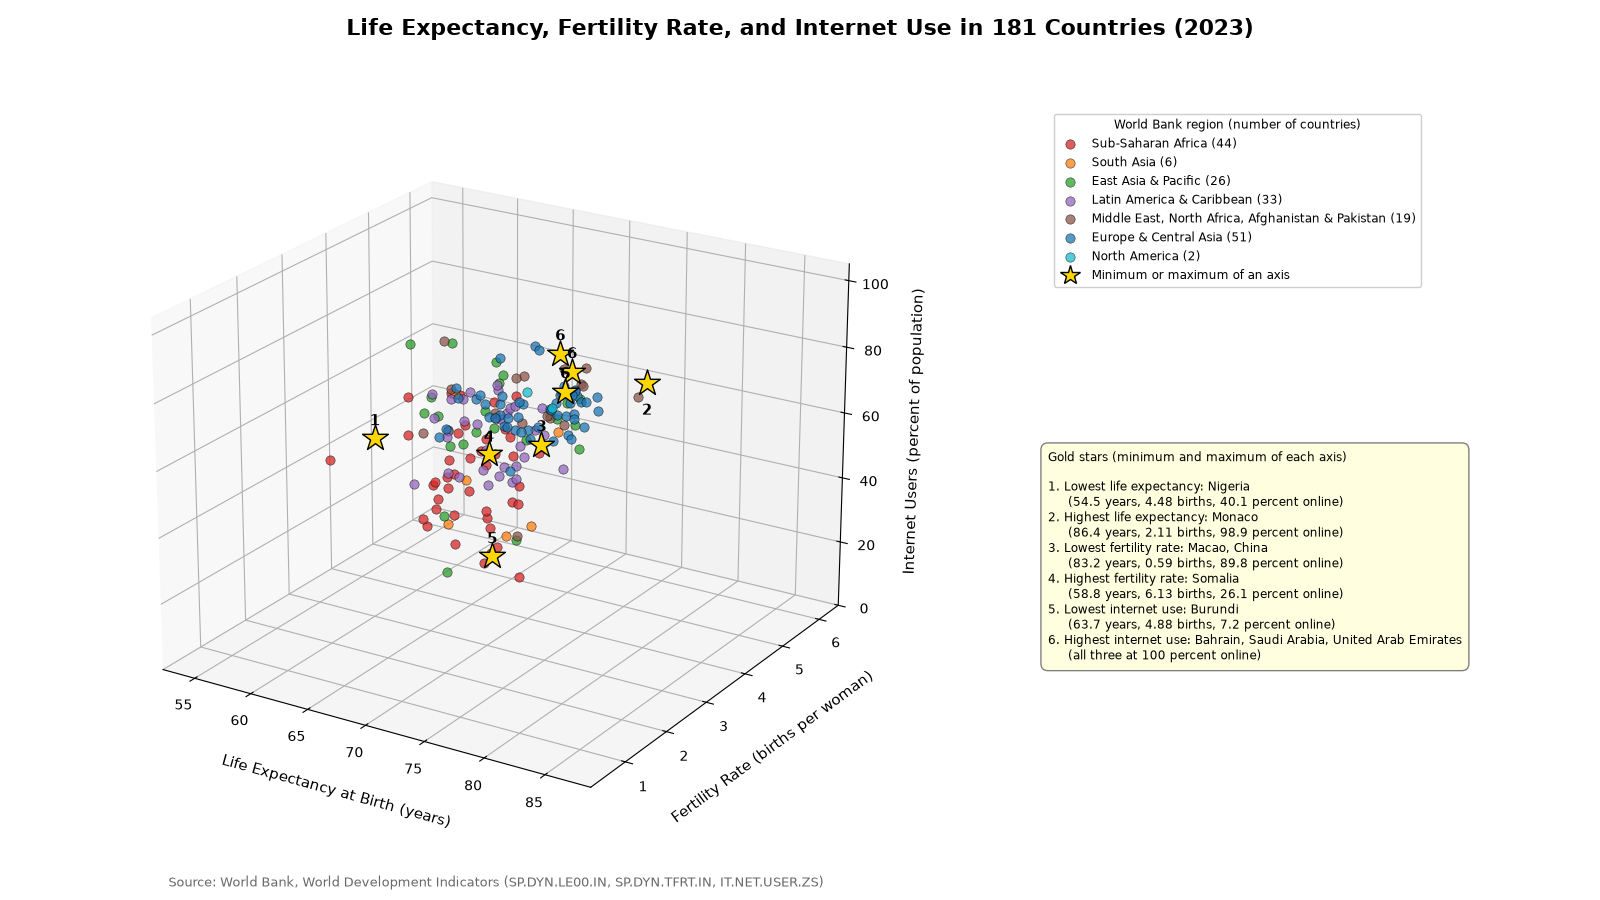

Saved scatter3d_default_angle.png


In [7]:
region_colors = {
    'Sub-Saharan Africa': '#d62728',
    'South Asia': '#ff7f0e',
    'East Asia & Pacific': '#2ca02c',
    'Latin America & Caribbean': '#9467bd',
    'Middle East, North Africa, Afghanistan & Pakistan': '#8c564b',
    'Europe & Central Asia': '#1f77b4',
    'North America': '#17becf'
}

def draw_scatter(elev=22, azim=-58, large_text=False, interactive=True):
    # large_text=True makes a taller figure with bigger text and puts the legend and key below the plot
    k = 1.6 if large_text else 1.0
    if large_text:
        # A plain Figure is drawn by Matplotlib's standard image engine, not the ipympl widget
        fig = plt.figure(figsize=(16, 15)) if interactive else Figure(figsize=(16, 15))
        ax = fig.add_axes([0.02, 0.36, 0.96, 0.58], projection='3d', computed_zorder=False)
    else:
        fig = plt.figure(figsize=(16, 9)) if interactive else Figure(figsize=(16, 9))
        ax = fig.add_axes([0.0, 0.04, 0.62, 0.86], projection='3d', computed_zorder=False)

    for region, color in region_colors.items():
        subset = countries[countries['region'] == region]
        ax.scatter(subset[life], subset[fert], subset[net], zorder=2,
                   color=color, marker='o', s=45 * k, alpha=0.75,
                   edgecolor='black', linewidth=0.4, depthshade=False, label=f'{region} ({len(subset)})')

    # Highlight all six extremes (minimum and maximum of every axis) with numbered gold stars
    key_lines = []
    for number, (label, row) in enumerate(extremes.items(), start=1):
        if label == 'Highest internet use':
            rows = countries[countries[net] == countries[net].max()]
            names = ', '.join(rows['country'])
        else:
            rows = countries[countries['country'] == row['country']]
            names = row['country']
        ax.scatter(rows[life], rows[fert], rows[net], marker='*', s=380 * k, color='gold',
                   edgecolor='black', linewidth=1, depthshade=False, zorder=5)
        for _, r in rows.iterrows():
            z_shift = -9 if label == 'Highest life expectancy' else 4
            ax.text(r[life], r[fert], r[net] + z_shift, str(number), fontsize=11 * k,
                    fontweight='bold', ha='center', zorder=6)
        if label == 'Highest internet use':
            key_lines.append(f"{number}. {label}: {names}\n     (all three at 100 percent online)")
            continue
        key_lines.append(f"{number}. {label}: {names}\n     ({row[life]:.1f} years, {row[fert]:.2f} births, {row[net]:.1f} percent online)")
    key_x, key_y = (0.47, 0.30) if large_text else (0.655, 0.50)
    fig.text(key_x, key_y, 'Gold stars (minimum and maximum of each axis)\n\n' + '\n'.join(key_lines),
             fontsize=10 * k * 0.85, va='top',
             bbox=dict(boxstyle='round,pad=0.6', facecolor='lightyellow', edgecolor='gray'))

    ax.set_xlabel('Life Expectancy at Birth (years)', labelpad=14 * k, fontsize=11 * k)
    ax.set_ylabel('Fertility Rate (births per woman)', labelpad=14 * k, fontsize=11 * k)
    ax.set_zlabel('Internet Users (percent of population)', labelpad=10 * k, fontsize=11 * k)
    ax.tick_params(labelsize=10 * k)
    fig.suptitle('Life Expectancy, Fertility Rate, and Internet Use in 181 Countries (2023)',
                 fontsize=16 * (1.3 if large_text else 1), fontweight='bold', y=0.98)
    ax.set_zlim(0, 105)
    ax.view_init(elev=elev, azim=azim)
    if large_text:
        ax.set_box_aspect(None, zoom=1.2)

    star = Line2D([0], [0], marker='*', color='w', markerfacecolor='gold',
                  markeredgecolor='black', markersize=15, label='Minimum or maximum of an axis')
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles + [star], labels + [star.get_label()], title='World Bank region (number of countries)',
              loc='upper left', bbox_to_anchor=(0.03, 0.30) if large_text else (0.655, 0.88),
              fontsize=10 * k * 0.85, title_fontsize=10.5 * k * 0.85, markerscale=1.0, framealpha=0.95)
    fig.text(0.5 if large_text else 0.31, 0.015, 'Source: World Bank, World Development Indicators (SP.DYN.LE00.IN, SP.DYN.TFRT.IN, IT.NET.USER.ZS)',
             ha='center', fontsize=9 * (1.4 if large_text else 1), color='dimgray')
    return fig, ax

# Interactive chart: click and drag to rotate it
fig, ax = draw_scatter()
plt.show()

# The PNG for the discussion post is drawn from a separate plain Figure (not the ipympl widget),
# so the saved file is always complete even while the interactive chart is still drawing.
fig_png, ax_png = draw_scatter(interactive=False)
fig_png.savefig('scatter3d_default_angle.png', dpi=150, bbox_inches='tight')
print('Saved scatter3d_default_angle.png')

### Saving a second, rotated angle for the discussion post
This is the same chart turned so that fertility rate runs across the front, which makes the split between low-fertility and high-fertility countries easier to see. It is shown as a saved picture because the interactive view above is the one meant for rotating.

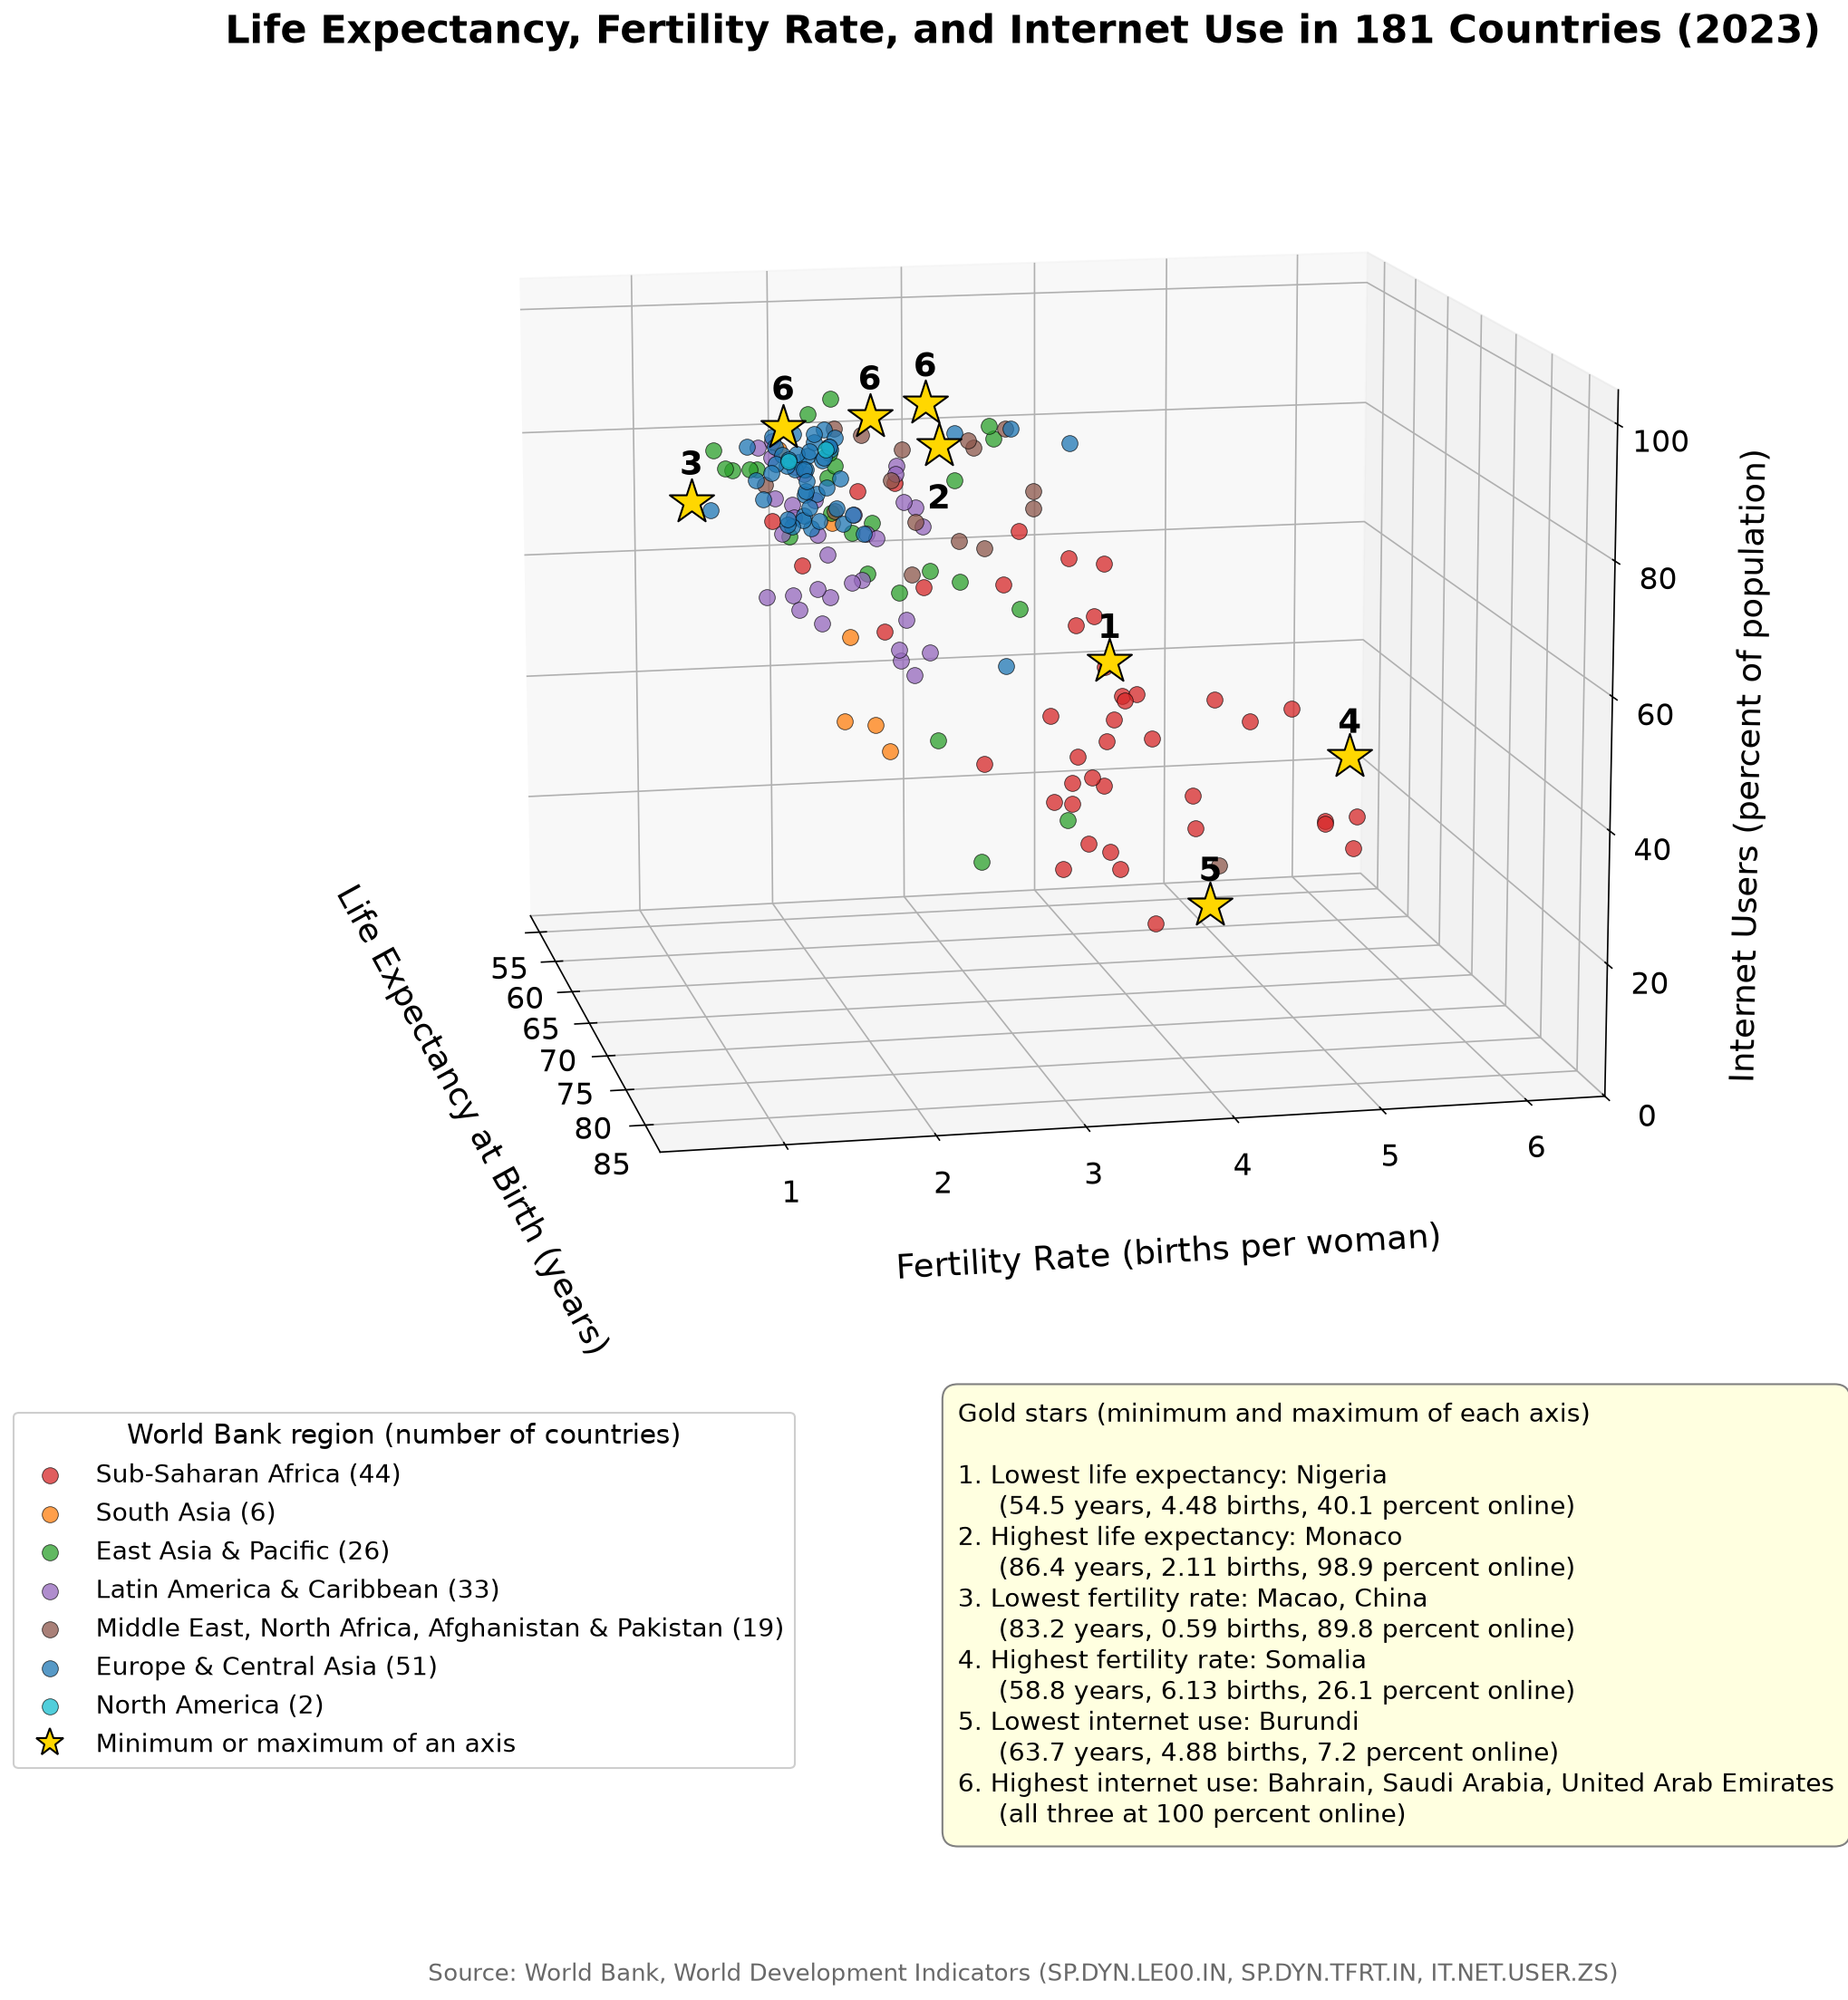

In [8]:
from IPython.display import Image, display

# The rotatable (ipympl) chart above is the interactive one. This second angle is built
# as a plain Matplotlib Figure that is NOT connected to the ipympl widget, so it is drawn
# straight to a PNG file and can never show up blank. The PNG is then displayed below.
fig2, ax2 = draw_scatter(elev=12, azim=-12, large_text=True, interactive=False)
fig2.savefig('scatter3d_rotated_angle.png', dpi=150, bbox_inches='tight')
display(Image(filename='scatter3d_rotated_angle.png'))

### Numbers behind the conclusions

In [9]:
print('Correlations between the three variables:')
print(countries[[life, fert, net]].corr().round(3))
print()
print('Regional medians:')
countries.groupby('region')[[life, fert, net]].median().round(2)

Correlations between the three variables:
                            life_expectancy_years  fertility_births_per_woman  \
life_expectancy_years                       1.000                      -0.830   
fertility_births_per_woman                 -0.830                       1.000   
internet_users_percent                      0.805                      -0.839   

                            internet_users_percent  
life_expectancy_years                        0.805  
fertility_births_per_woman                  -0.839  
internet_users_percent                       1.000  

Regional medians:


,life_expectancy_years,fertility_births_per_woman,internet_users_percent
region,,,
East Asia & Pacific,72.51,1.91,83.39
Europe & Central Asia,79.60,1.46,91.04
Latin America & Caribbean,73.84,1.78,77.30
"Middle East, North Africa, Afghanistan & Pakistan",77.81,2.36,87.04
North America,80.01,1.44,93.84
South Asia,73.82,1.97,55.73
Sub-Saharan Africa,63.90,4.04,34.22


In [10]:
high_net = countries[countries[net] >= 90]
low_net = countries[countries[net] < 30]
print(f'Countries at or above 90 percent internet use: {len(high_net)}')
print(f'  median life expectancy {high_net[life].median():.1f} years, median fertility {high_net[fert].median():.2f}')
print(f'Countries below 30 percent internet use: {len(low_net)}')
print(f'  median life expectancy {low_net[life].median():.1f} years, median fertility {low_net[fert].median():.2f}')
print('  regions:', low_net['region'].value_counts().to_dict())
print()
print(f'Countries below the replacement fertility rate of 2.1: {(countries[fert] < 2.1).sum()} of {len(countries)}')
print()
print('Countries with life expectancy above 80 years and fertility above 2.2 births per woman:')
countries[(countries[life] > 80) & (countries[fert] > 2.2)][['country', life, fert, net]]

Countries at or above 90 percent internet use: 50
  median life expectancy 81.7 years, median fertility 1.44
Countries below 30 percent internet use: 20
  median life expectancy 63.9 years, median fertility 4.23
  regions: {'Sub-Saharan Africa': 17, 'East Asia & Pacific': 2, 'Middle East, North Africa, Afghanistan & Pakistan': 1}

Countries below the replacement fertility rate of 2.1: 98 of 181

Countries with life expectancy above 80 years and fertility above 2.2 births per woman:


,country,life_expectancy_years,fertility_births_per_woman,internet_users_percent
80,Israel,83.195,2.850,87.038
128,Oman,80.031,2.525,95.252


In [11]:
countries[countries['country'].isin(['United States', 'Mexico', 'India', 'China', 'Japan', 'South Korea'])][['country', life, fert, net]].round(2)

,country,life_expectancy_years,fertility_births_per_woman,internet_users_percent
34,China,77.95,1.00,90.60
75,India,72.00,1.98,60.25
83,Japan,84.04,1.20,85.01
88,South Korea,83.43,0.72,97.42
110,Mexico,75.07,1.91,81.18
173,United States,78.39,1.62,93.53
